# Main results

Compares four models on the phased test stream:

- **Static**: ARF trained on Normal and ECL, never updated.
- **Online**: the same ARF, updated after every prediction (test-then-train).
- **Periodic**: batch random forest rebuilt every 5000 samples on all data seen so far.
- **Oracle**: batch random forest that also sees EDFA and NLI samples before the stream (upper bound).

Produces Figs. 5-8 of the paper and the results over ten seeds.

In [4]:
import os
import time
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from sklearn.metrics import confusion_matrix, f1_score

from utils import (CLASSES, CLASS_NAMES, PHASE_NAMES, load_dataset, make_training_set,
                   make_oracle_extra, make_phased_stream, make_arf, make_batch_forest,
                   train_river_model, run_stream, run_batch_retraining, run_batch_model,
                   rolling_accuracy, rolling_auc, window_auc, recovery_time)

DATA_DIR = "data"      # folder containing the two dataset CSV files
FIG_DIR = "figures"
SEED = 42
N_SEEDS = 10

os.makedirs(FIG_DIR, exist_ok=True)

## Data

In [5]:
train_df, test_df = load_dataset(DATA_DIR)

X_train, y_train = make_training_set(train_df, seed=SEED)
X_extra, y_extra = make_oracle_extra(train_df, seed=SEED)
X_stream, y_stream, phase_starts = make_phased_stream(test_df, seed=SEED)

print("training set:", np.bincount(y_train, minlength=4))
print("oracle extra:", np.bincount(y_extra, minlength=4))
print("stream:      ", np.bincount(y_stream, minlength=4))

training set: [10000 10000     0     0]
oracle extra: [   0    0 1994 2006]
stream:       [8399 6641 5805 4155]


## Run the four models

In [6]:
def run_all_models(X_train, y_train, X_extra, y_extra, X_stream, y_stream, retrain_at, seed):
    arf = train_river_model(make_arf(seed), X_train, y_train)

    results = {}
    results["Static"] = run_stream(arf, X_stream, y_stream, learn=False)
    results["Online"] = run_stream(arf, X_stream, y_stream)

    preds, probas, fit_times = run_batch_retraining(X_train, y_train, X_stream, y_stream,
                                                    retrain_at, seed)
    results["Periodic"] = (preds, probas)

    oracle = make_batch_forest(seed).fit(np.vstack([X_train, X_extra]),
                                         np.concatenate([y_train, y_extra]))
    results["Oracle"] = run_batch_model(oracle, X_stream)
    return results, fit_times


# Retraining at the start of every phase, as in the submitted paper.
retrain_at = phase_starts[1:]
results, fit_times = run_all_models(X_train, y_train, X_extra, y_extra,
                                    X_stream, y_stream, retrain_at, SEED)
MODELS = list(results)

In [7]:
edfa_onset, nli_onset = phase_starts[1], phase_starts[2]

rows = []
for name, (preds, probas) in results.items():
    rows.append({
        "model": name,
        "accuracy": (preds == y_stream).mean(),
        "macro-F1": f1_score(y_stream, preds, average="macro"),
        "AUC": window_auc(y_stream, probas),
        "errors": int((preds != y_stream).sum()),
        "recovery after EDFA": recovery_time(y_stream, preds, edfa_onset),
        "recovery after NLI": recovery_time(y_stream, preds, nli_onset),
    })
summary = pd.DataFrame(rows).set_index("model").round(4)
summary

,accuracy,macro-F1,AUC,errors,recovery after EDFA,recovery after NLI
model,,,,,,
Static,0.6016,0.3762,0.6764,9960,NaN,NaN
Online,0.9955,0.9957,0.9994,113,394.0,59.0
Periodic,0.8864,0.8736,0.9142,2839,NaN,NaN
Oracle,0.9989,0.9990,0.9994,28,0.0,0.0


Recovery time is the number of samples after an onset until the error rate over the
next 200 samples drops below 1%. Empty means the model did not recover within the phase.

## Fig. 5: rolling accuracy and AUC

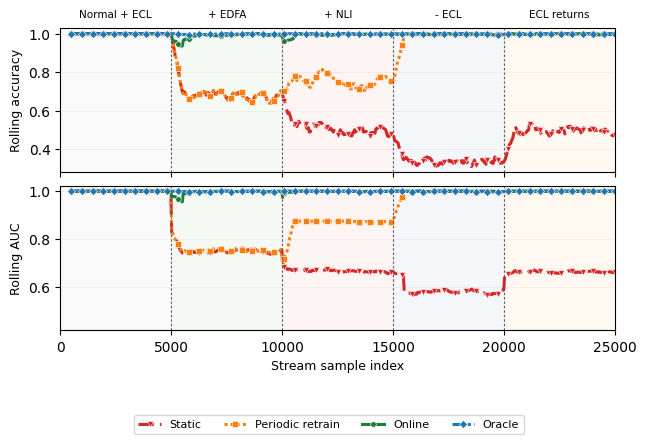

In [8]:
STYLE = {
    "Static":   dict(color="#d62728", ls=(0, (5, 2)),       marker="v", label="Static"),
    "Periodic": dict(color="#ff7f0e", ls=(0, (1, 1)),       marker="s", label="Periodic retrain"),
    "Online":   dict(color="#1b7f3b", ls="-",               marker="o", label="Online"),
    "Oracle":   dict(color="#1f77b4", ls=(0, (4, 1, 1, 1)), marker="D", label="Oracle"),
}
BAND_COLORS = ["#f7f7f7", "#eef6ee", "#fdeeee", "#eef1f8", "#fff6e8"]


def shade_phases(ax, n):
    edges = phase_starts + [n]
    for k in range(len(phase_starts)):
        ax.axvspan(edges[k], edges[k + 1], color=BAND_COLORS[k], alpha=0.6, zorder=0)
    for start in phase_starts[1:]:
        ax.axvline(start, color="0.35", ls=(0, (2, 2)), lw=0.8)


fig, (ax_acc, ax_auc) = plt.subplots(2, 1, figsize=(7.16, 4.2), sharex=True,
                                     gridspec_kw={"hspace": 0.10})
for name in ["Static", "Periodic", "Online", "Oracle"]:
    preds, probas = results[name]
    x, acc = rolling_accuracy(y_stream, preds)
    _, auc = rolling_auc(y_stream, probas)
    s = STYLE[name]
    kw = dict(color=s["color"], ls=s["ls"], lw=2.2, marker=s["marker"], ms=4,
              markevery=12, mec="white", mew=0.4)
    ax_acc.plot(x, acc, label=s["label"], **kw)
    ax_auc.plot(x, auc, **kw)

for ax in (ax_acc, ax_auc):
    shade_phases(ax, len(y_stream))
    ax.grid(alpha=0.2, lw=0.5)
    ax.margins(x=0)

ax_acc.set_ylim(0.28, 1.03)
ax_auc.set_ylim(0.42, 1.02)
ax_acc.set_ylabel("Rolling accuracy", fontsize=9)
ax_auc.set_ylabel("Rolling AUC", fontsize=9)
ax_auc.set_xlabel("Stream sample index", fontsize=9)

edges = phase_starts + [len(y_stream)]
for k, name in enumerate(PHASE_NAMES):
    ax_acc.text((edges[k] + edges[k + 1]) / 2, 1.06, name, ha="center", va="bottom",
                fontsize=7.5, transform=ax_acc.get_xaxis_transform())

handles, labels = ax_acc.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.10))
fig.subplots_adjust(bottom=0.16)
fig.savefig(f"{FIG_DIR}/fig5_rolling_accuracy_auc.pdf", bbox_inches="tight")
plt.show()

## Fig. 6: cumulative misclassifications

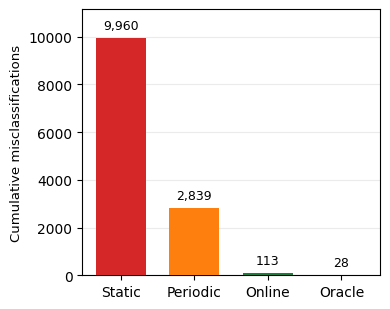

In [9]:
errors = [summary.loc[name, "errors"] for name in ["Static", "Periodic", "Online", "Oracle"]]
colors = [STYLE[name]["color"] for name in ["Static", "Periodic", "Online", "Oracle"]]

fig, ax = plt.subplots(figsize=(4.0, 3.2))
bars = ax.bar(["Static", "Periodic", "Online", "Oracle"], errors, color=colors, width=0.68, zorder=3)
ax.bar_label(bars, labels=[f"{e:,}" for e in errors], padding=4, fontsize=9)
ax.set_ylim(0, max(errors) * 1.12)
ax.set_ylabel("Cumulative misclassifications", fontsize=9.5)
ax.grid(alpha=0.25, axis="y")
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig6_cumulative_errors.pdf", bbox_inches="tight")
plt.show()

## Fig. 7: confusion matrices

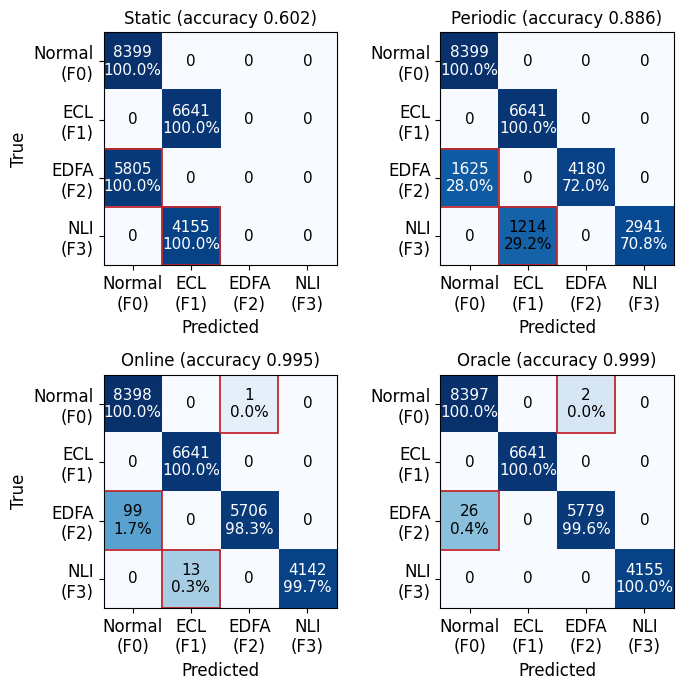

In [10]:
tick_labels = [f"{n}\n(F{c})" for c, n in zip(CLASSES, CLASS_NAMES)]

fig, axes = plt.subplots(2, 2, figsize=(7.16, 7.0))
for ax, name in zip(axes.ravel(), ["Static", "Periodic", "Online", "Oracle"]):
    preds, _ = results[name]
    cm = confusion_matrix(y_stream, preds, labels=CLASSES)
    row_pct = 100 * cm / cm.sum(axis=1, keepdims=True)

    # Log colour scale so that small error counts are still visible.
    ax.imshow(np.where(cm == 0, 0.4, cm), cmap="Blues", norm=LogNorm(vmin=0.4, vmax=cm.max()))
    for i in CLASSES:
        for j in CLASSES:
            text = "0" if cm[i, j] == 0 else f"{cm[i, j]}\n{row_pct[i, j]:.1f}%"
            ax.text(j, i, text, ha="center", va="center", fontsize=11,
                    color="white" if cm[i, j] > 0.15 * cm.max() else "black")
            if i != j and cm[i, j] > 0:
                ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False,
                                           edgecolor="#c1272d", lw=1.3))
    ax.set_xticks(CLASSES, tick_labels, fontsize=12)
    ax.set_yticks(CLASSES, tick_labels, fontsize=12)
    ax.set_xlabel("Predicted", fontsize=12)
    ax.set_title(f"{name} (accuracy {np.trace(cm) / cm.sum():.3f})", fontsize=12)
for ax in axes[:, 0]:
    ax.set_ylabel("True", fontsize=12)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig7_confusion_matrices.pdf", bbox_inches="tight")
plt.show()

## Where the online model makes its errors

Errors in the first samples after a new failure appears are adaptation lag. The rest are
spread over the stream and can be compared with the oracle's errors.

In [11]:
LAG_WINDOW = 500

for name in ["Online", "Oracle"]:
    wrong = results[name][0] != y_stream
    after_edfa = int(wrong[edfa_onset:edfa_onset + LAG_WINDOW].sum())
    after_nli = int(wrong[nli_onset:nli_onset + LAG_WINDOW].sum())
    print(f"{name:7s} total {wrong.sum():4d} | first {LAG_WINDOW} after EDFA onset: {after_edfa:3d}"
          f" | first {LAG_WINDOW} after NLI onset: {after_nli:3d}"
          f" | elsewhere: {wrong.sum() - after_edfa - after_nli}")

Online  total  113 | first 500 after EDFA onset:  32 | first 500 after NLI onset:  13 | elsewhere: 68
Oracle  total   28 | first 500 after EDFA onset:   2 | first 500 after NLI onset:   0 | elsewhere: 26


In [12]:
from collections import Counter

def in_lag_window(t):
    return (edfa_onset <= t < edfa_onset + LAG_WINDOW) or (nli_onset <= t < nli_onset + LAG_WINDOW)

for name in ["Online", "Oracle"]:
    preds = results[name][0]
    wrong = np.where(preds != y_stream)[0]
    after_onset = Counter((CLASS_NAMES[y_stream[t]], CLASS_NAMES[preds[t]]) for t in wrong if in_lag_window(t))
    elsewhere = Counter((CLASS_NAMES[y_stream[t]], CLASS_NAMES[preds[t]]) for t in wrong if not in_lag_window(t))
    print(name, "| after onsets:", dict(after_onset), "| elsewhere:", dict(elsewhere))

Online | after onsets: {('EDFA', 'Normal'): 31, ('Normal', 'EDFA'): 1, ('NLI', 'ECL'): 13} | elsewhere: {('EDFA', 'Normal'): 68}
Oracle | after onsets: {('EDFA', 'Normal'): 2} | elsewhere: {('EDFA', 'Normal'): 24, ('Normal', 'EDFA'): 2}


## Per-class recall and macro-F1 over the stream

Unlike the rolling AUC, both are defined in every window, including windows where a
class is absent (that class is simply left out of the recall plot).

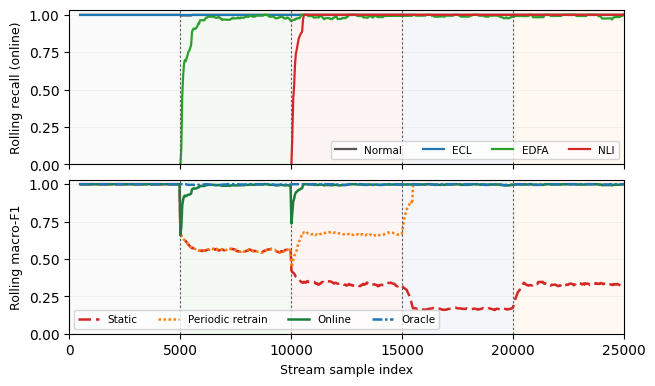

In [13]:
def rolling_recall(y, preds, cls, window=500, step=40):
    ends, values = [], []
    for e in range(window, len(y) + 1, step):
        mask = y[e - window:e] == cls
        ends.append(e)
        values.append((preds[e - window:e][mask] == cls).mean() if mask.any() else np.nan)
    return np.array(ends), np.array(values)


def rolling_macro_f1(y, preds, window=500, step=40):
    ends = np.arange(window, len(y) + 1, step)
    values = [f1_score(y[e - window:e], preds[e - window:e], average="macro") for e in ends]
    return ends, np.array(values)


fig, (ax_rec, ax_f1) = plt.subplots(2, 1, figsize=(7.16, 4.2), sharex=True,
                                    gridspec_kw={"hspace": 0.10})

online_preds = results["Online"][0]
for cls, color in zip(CLASSES, ["#555555", "#1f77b4", "#2ca02c", "#d62728"]):
    x, recall = rolling_recall(y_stream, online_preds, cls)
    ax_rec.plot(x, recall, color=color, lw=1.6, label=CLASS_NAMES[cls])
ax_rec.set_ylabel("Rolling recall (online)", fontsize=9)
ax_rec.legend(fontsize=7.5, ncol=4, loc="lower right")

for name in ["Static", "Periodic", "Online", "Oracle"]:
    x, f1 = rolling_macro_f1(y_stream, results[name][0])
    s = STYLE[name]
    ax_f1.plot(x, f1, color=s["color"], ls=s["ls"], lw=1.8, label=s["label"])
ax_f1.set_ylabel("Rolling macro-F1", fontsize=9)
ax_f1.set_xlabel("Stream sample index", fontsize=9)
ax_f1.legend(fontsize=7.5, ncol=4, loc="lower left")

for ax in (ax_rec, ax_f1):
    shade_phases(ax, len(y_stream))
    ax.set_ylim(0, 1.03)
    ax.margins(x=0)
    ax.grid(alpha=0.2, lw=0.5)
fig.savefig(f"{FIG_DIR}/recall_and_macro_f1.pdf", bbox_inches="tight")
plt.show()

## Results over ten seeds

The seed sets both the random mixing of the stream and the randomness of the models,
so every run sees a different stream realisation.

In [17]:
seed_rows = []
for seed in range(N_SEEDS):
    Xs, ys, starts = make_phased_stream(test_df, seed=seed)
    res, _ = run_all_models(X_train, y_train, X_extra, y_extra, Xs, ys, starts[1:], seed)
    for name, (preds, probas) in res.items():
        seed_rows.append({"seed": seed, "model": name,
                          "accuracy": (preds == ys).mean(),
                          "macro-F1": f1_score(ys, preds, average="macro"),
                          "AUC": window_auc(ys, probas),
                          "mean rolling accuracy": rolling_accuracy(ys, preds)[1].mean(),
                          "mean rolling AUC": np.nanmean(rolling_auc(ys, probas)[1]),
                          "errors": int((preds != ys).sum()),
                          "recovery after EDFA": recovery_time(ys, preds, starts[1]),
                          "recovery after NLI": recovery_time(ys, preds, starts[2])})
    print(f"seed {seed} done")

seed_results = pd.DataFrame(seed_rows)
seed_results.to_csv("results_seeds.csv", index=False)
seed_results.drop(columns="seed").groupby("model").agg(["mean", "std"]).round(4)

seed 0 done
seed 1 done
seed 2 done
seed 3 done
seed 4 done
seed 5 done
seed 6 done
seed 7 done
seed 8 done
seed 9 done


accuracy         macro-F1             AUC          \
             mean     std     mean     std    mean     std   
model                                                        
Online     0.9958  0.0005   0.9961  0.0005  0.9995  0.0001   
Oracle     0.9985  0.0004   0.9986  0.0004  0.9993  0.0001   
Periodic   0.8823  0.0021   0.8688  0.0021  0.9104  0.0033   
Static     0.6007  0.0031   0.3759  0.0012  0.6777  0.0008   

         mean rolling accuracy         mean rolling AUC          errors  \
                          mean     std             mean     std    mean   
model                                                                     
Online                  0.9958  0.0005           0.9990  0.0001   104.2   
Oracle                  0.9985  0.0004           0.9993  0.0001    37.5   
Periodic                0.8800  0.0022           0.9195  0.0039  2943.5   
Static                  0.5979  0.0033           0.7303  0.0010  9982.0   

                  recovery after EDFA           recovery after NLI            
              std                mean       std               mean       std  
model                                                                         
Online    12.6210               254.0  235.9374              102.3  118.0754  
Oracle    10.7108                22.7   56.1982                0.0    0.0000  
Periodic  52.3116                 NaN       NaN                NaN       NaN  
Static    76.5622                 NaN       NaN                NaN       NaN

In [18]:
METRICS = ["accuracy", "AUC", "mean rolling accuracy", "mean rolling AUC"]
per_seed = seed_results.pivot(index="seed", columns="model", values=METRICS)

rows = []
for metric in METRICS:
    for baseline in ["Periodic", "Static"]:
        online, base = per_seed[metric]["Online"], per_seed[metric][baseline]
        gain = 100 * (online - base) / base
        rows.append({"metric": metric, "relative to": baseline,
                     "improvement (%)": f"{gain.mean():.1f} ± {gain.std():.1f}"})
pd.DataFrame(rows)

,metric,relative to,improvement (%)
0,accuracy,Periodic,12.9 ± 0.3
1,accuracy,Static,65.8 ± 0.9
2,AUC,Periodic,9.8 ± 0.4
3,AUC,Static,47.5 ± 0.2
4,mean rolling accuracy,Periodic,13.2 ± 0.3
5,mean rolling accuracy,Static,66.6 ± 0.9
6,mean rolling AUC,Periodic,8.6 ± 0.5
7,mean rolling AUC,Static,36.8 ± 0.2


In [11]:
seed_results.groupby("model")[["recovery after EDFA", "recovery after NLI"]].count()

,recovery after EDFA,recovery after NLI
model,,
Online,10,10
Oracle,10,10
Periodic,0,0
Static,0,0


In [12]:
seed_results.groupby("model")[["recovery after EDFA", "recovery after NLI"]].describe()

recovery after EDFA                                               \
                       count   mean         std   min   25%    50%    75%   
model                                                                       
Online                  10.0  254.0  235.937374  43.0  55.5  156.5  427.0   
Oracle                  10.0   22.7   56.198161   0.0   0.0    0.0    0.0   
Periodic                 0.0    NaN         NaN   NaN   NaN    NaN    NaN   
Static                   0.0    NaN         NaN   NaN   NaN    NaN    NaN   

                recovery after NLI                                        \
            max              count   mean         std   min    25%   50%   
model                                                                      
Online    660.0               10.0  102.3  118.075353  12.0  35.25  59.0   
Oracle    176.0               10.0    0.0    0.000000   0.0   0.00   0.0   
Periodic    NaN                0.0    NaN         NaN   NaN    NaN   NaN   
Static      NaN                0.0    NaN         NaN   NaN    NaN   NaN   

                        
            75%    max  
model                   
Online    136.0  405.0  
Oracle      0.0    0.0  
Periodic    NaN    NaN  
Static      NaN    NaN

## Other class-introduction orders

The paper's stream introduces EDFA before NLI. Two other orders are tested here,
each over the same ten seeds.

In [13]:
ORDERS = {
    "NLI then EDFA":         [[0, 1], [0, 1, 3], [0, 1, 2, 3], [0, 2, 3], [0, 1, 2, 3]],
    "EDFA and NLI together": [[0, 1], [0, 1, 2, 3], [0, 1, 2, 3], [0, 2, 3], [0, 1, 2, 3]],
}

# The paper's order was already run in the previous cell.
order_rows = [{"order": "EDFA then NLI (paper)", "model": r["model"], "seed": r["seed"],
               "errors": r["errors"]} for r in seed_rows]
for order_name, phase_classes in ORDERS.items():
    for seed in range(N_SEEDS):
        Xs, ys, starts = make_phased_stream(test_df, phase_classes=phase_classes, seed=seed)
        res, _ = run_all_models(X_train, y_train, X_extra, y_extra, Xs, ys, starts[1:], seed)
        for name, (preds, _) in res.items():
            order_rows.append({"order": order_name, "model": name, "seed": seed,
                               "errors": int((preds != ys).sum())})
    print(f"{order_name} done")

order_results = pd.DataFrame(order_rows)
order_results.to_csv("results_class_orders.csv", index=False)

# Misclassifications as "mean ± std", one row per order and one column per model.
(order_results.groupby(["order", "model"], sort=False)["errors"]
 .agg(lambda e: f"{e.mean():.0f} ± {e.std():.0f}")
 .unstack("model")[["Static", "Periodic", "Online", "Oracle"]])

NLI then EDFA done
EDFA and NLI together done


model,Static,Periodic,Online,Oracle
order,,,,
EDFA then NLI (paper),9982 ± 77,2944 ± 52,104 ± 13,38 ± 11
NLI then EDFA,9982 ± 77,2950 ± 61,95 ± 14,28 ± 8
EDFA and NLI together,10803 ± 53,2519 ± 45,107 ± 31,35 ± 10


## Fig. 8: per-sample latency

Static and online are the same ARF; the online model also learns from each sample.
Each pass times 2000 stream samples and the result is averaged over 100 passes.

In [14]:
N_PASSES = 100
N_TIMED = 2000

arf = train_river_model(make_arf(SEED), X_train, y_train)
idx = np.random.default_rng(0).choice(len(y_stream), N_TIMED, replace=False)
samples = X_stream.iloc[idx].to_dict("records")
labels = y_stream[idx]

predict_ms, online_ms = [], []
for _ in range(N_PASSES):
    model = deepcopy(arf)
    tic = time.perf_counter()
    for x in samples:
        model.predict_one(x)
    predict_ms.append((time.perf_counter() - tic) / N_TIMED * 1000)

    model = deepcopy(arf)
    tic = time.perf_counter()
    for x, label in zip(samples, labels):
        model.predict_one(x)
        model.learn_one(x, int(label))
    online_ms.append((time.perf_counter() - tic) / N_TIMED * 1000)

static_mean, online_mean = np.mean(predict_ms), np.mean(online_ms)
print(f"static: {static_mean:.4f} +/- {np.std(predict_ms):.4f} ms per sample")
print(f"online: {online_mean:.4f} +/- {np.std(online_ms):.4f} ms per sample")
print(f"periodic: {len(fit_times)} retrains, {sum(fit_times):.2f} s in total")

static: 0.0862 +/- 0.0101 ms per sample
online: 0.6152 +/- 0.0352 ms per sample
periodic: 4 retrains, 0.28 s in total


In [19]:
# The data each retraining sees: the initial training set plus the stream so far.
retrain_sets = [(np.vstack([X_train.to_numpy(), X_stream.to_numpy()[:t]]),
                 np.concatenate([y_train, y_stream[:t]])) for t in retrain_at]

total_s, each_s = [], []
for _ in range(N_PASSES):
    times = []
    for X_all, y_all in retrain_sets:
        tic = time.perf_counter()
        make_batch_forest(SEED).fit(X_all, y_all)
        times.append(time.perf_counter() - tic)
    total_s.append(sum(times))
    each_s += times

print(f"periodic: {len(retrain_sets)} retrains, {np.mean(total_s):.2f} +/- {np.std(total_s):.2f} s in total, "
      f"{np.mean(each_s):.3f} s per retrain on average")

periodic: 4 retrains, 0.27 +/- 0.02 s in total, 0.067 s per retrain on average


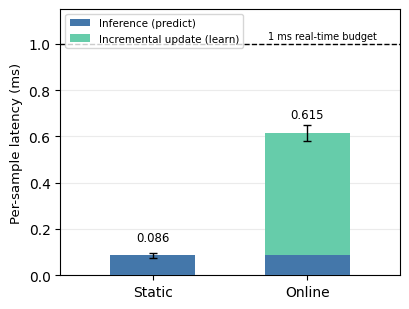

In [15]:
fig, ax = plt.subplots(figsize=(4.2, 3.2))
ax.bar([0, 1], [static_mean, static_mean], width=0.55, color="#4477aa",
       label="Inference (predict)", zorder=3)
ax.bar([1], [online_mean - static_mean], bottom=[static_mean], width=0.55,
       color="#66ccaa", label="Incremental update (learn)", zorder=3)
ax.errorbar([0, 1], [static_mean, online_mean], yerr=[np.std(predict_ms), np.std(online_ms)],
            fmt="none", ecolor="black", capsize=3, lw=1, zorder=4)
for x, value in zip([0, 1], [static_mean, online_mean]):
    ax.text(x, value + 0.05, f"{value:.3f}", ha="center", va="bottom", fontsize=8.5)
ax.axhline(1.0, color="black", ls="--", lw=1)
ax.text(1.45, 1.01, "1 ms real-time budget", ha="right", va="bottom", fontsize=7)
ax.set_xticks([0, 1], ["Static", "Online"])
ax.set_xlim(-0.6, 1.6)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Per-sample latency (ms)", fontsize=9.5)
ax.legend(fontsize=7.5, loc="upper left")
ax.grid(alpha=0.25, axis="y")
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig8_latency.pdf", bbox_inches="tight")
plt.show()